LOADING DATASETS

Apple
----------------------------------------
Shape: (10000, 13)
Rows: 10,000
Columns: 13
Missing expected columns: []
Extra columns: []

X
----------------------------------------
Shape: (10000, 13)
Rows: 10,000
Columns: 13
Missing expected columns: []
Extra columns: []

Meta
----------------------------------------
Shape: (10000, 13)
Rows: 10,000
Columns: 13
Missing expected columns: []
Extra columns: []

DATASET SUMMARY
Domain  Rows  Columns  Unique Documents  Unique Topics  Unique Questions  Unique Contexts  Unique Claims  Unique Evidence  Unique Variants
 Apple 10000       13                 1             18                72               41           9966               42            10000
     X 10000       13                 1             18                72              246           7854              247            10000
  Meta 10000       13                 1             18                72              264           7818              265            1000

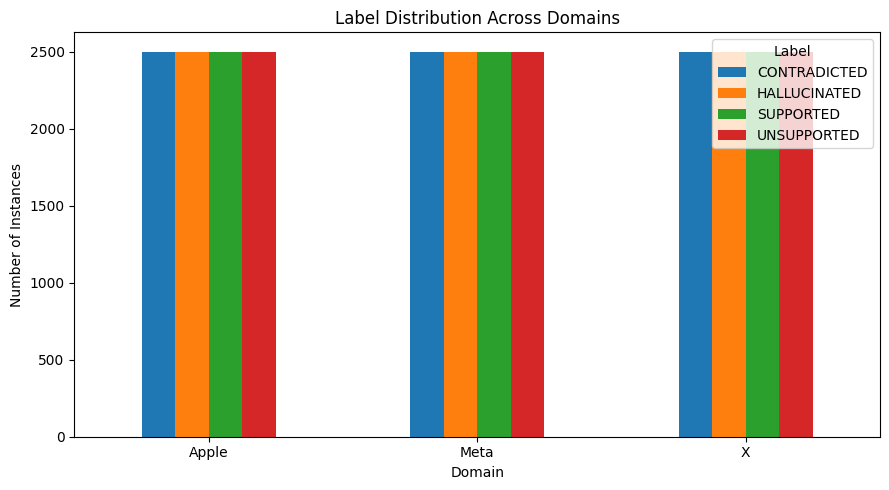

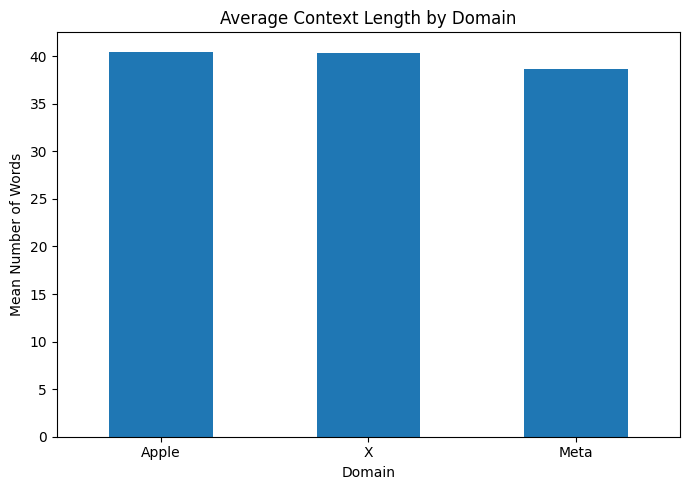

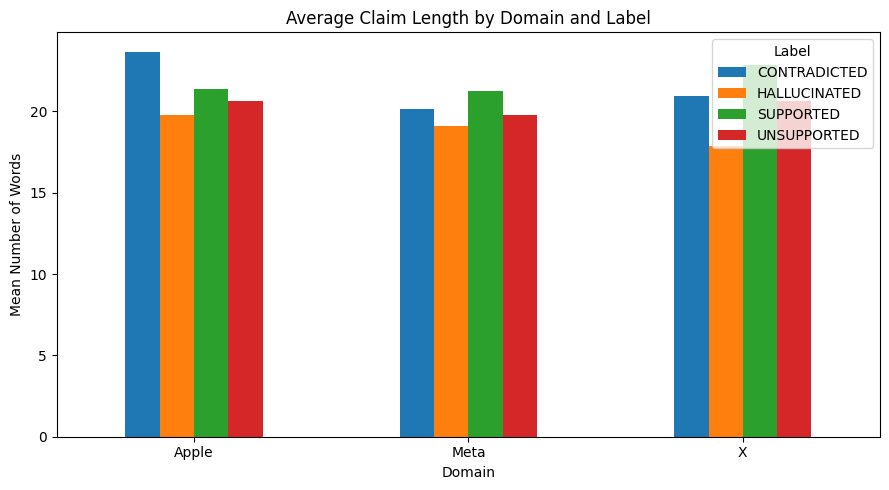


COMBINED DATASET
Total instances: 30,000
Unique normalized claims: 25,638
Unique source-fact groups: 162

Claims appearing in more than one domain: 0
Source-fact groups appearing in multiple domains: 0

FINAL DATASET QUALITY REPORT

Apple
--------------------------------------------------
Instances              : 10,000
Labels                 : 4
Topics                 : 18
Source-fact groups     : 126
Exact duplicates       : 0
Context-claim duplicates: 34
Missing contexts       : 0
Missing claims         : 0
Missing labels         : 0
Mean context words     : 40.49
Mean claim words       : 21.35
Mean evidence words    : 32.15

X
--------------------------------------------------
Instances              : 10,000
Labels                 : 4
Topics                 : 18
Source-fact groups     : 18
Exact duplicates       : 0
Context-claim duplicates: 354
Missing contexts       : 0
Missing claims         : 0
Missing labels         : 0
Mean context words     : 40.31
Mean claim words       : 

In [1]:
# ============================================================
# DATASET ANALYSIS FOR CONTEXTUAL HALLUCINATION DETECTION
# Apple / X / Meta
# ============================================================

import os
import re
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ============================================================
# 1. DATASET PATHS
# ============================================================

DATASETS = {
    "Apple": "apple_privacy_hallucination_10000.csv",
    "X": "x_privacy_policy_10000.csv",
    "Meta": "meta_human_rights_policy_10000.csv",
}

OUTPUT_DIR = Path("dataset_analysis")
OUTPUT_DIR.mkdir(exist_ok=True)

EXPECTED_COLUMNS = [
    "id",
    "document",
    "document_version",
    "topic",
    "question",
    "context",
    "claim",
    "label",
    "evidence",
    "source_lines",
    "generation_type",
    "difficulty",
    "variant_id",
]

EXPECTED_LABELS = [
    "SUPPORTED",
    "UNSUPPORTED",
    "CONTRADICTED",
    "HALLUCINATED",
]


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def normalize_text(text):
    """Normalize text for duplicate analysis."""
    if pd.isna(text):
        return ""

    text = str(text).lower().strip()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^\w\s]", "", text)

    return text


def word_count(text):
    if pd.isna(text):
        return 0

    return len(str(text).split())


def char_count(text):
    if pd.isna(text):
        return 0

    return len(str(text))


def lexical_overlap(context, claim):
    """Fraction of unique claim tokens found in context."""
    context_tokens = set(normalize_text(context).split())
    claim_tokens = set(normalize_text(claim).split())

    if len(claim_tokens) == 0:
        return 0.0

    return len(context_tokens & claim_tokens) / len(claim_tokens)


def safe_percent(x, total):
    if total == 0:
        return 0.0

    return 100 * x / total


# ============================================================
# 3. LOAD DATASETS
# ============================================================

datasets = {}

print("=" * 80)
print("LOADING DATASETS")
print("=" * 80)

for domain, path in DATASETS.items():

    df = pd.read_csv(path)

    datasets[domain] = df

    print(f"\n{domain}")
    print("-" * 40)
    print(f"Shape: {df.shape}")
    print(f"Rows: {len(df):,}")
    print(f"Columns: {len(df.columns)}")

    missing_columns = [
        col for col in EXPECTED_COLUMNS
        if col not in df.columns
    ]

    extra_columns = [
        col for col in df.columns
        if col not in EXPECTED_COLUMNS
    ]

    print(f"Missing expected columns: {missing_columns}")
    print(f"Extra columns: {extra_columns}")


# ============================================================
# 4. BASIC DATASET STATISTICS
# ============================================================

summary_rows = []

for domain, df in datasets.items():

    summary_rows.append({
        "Domain": domain,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Unique Documents":
            df["document"].nunique()
            if "document" in df else np.nan,
        "Unique Topics":
            df["topic"].nunique()
            if "topic" in df else np.nan,
        "Unique Questions":
            df["question"].nunique()
            if "question" in df else np.nan,
        "Unique Contexts":
            df["context"].nunique()
            if "context" in df else np.nan,
        "Unique Claims":
            df["claim"].nunique()
            if "claim" in df else np.nan,
        "Unique Evidence":
            df["evidence"].nunique()
            if "evidence" in df else np.nan,
        "Unique Variants":
            df["variant_id"].nunique()
            if "variant_id" in df else np.nan,
    })

summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 80)
print("DATASET SUMMARY")
print("=" * 80)

print(summary_df.to_string(index=False))

summary_df.to_csv(
    OUTPUT_DIR / "dataset_summary.csv",
    index=False
)


# ============================================================
# 5. MISSING VALUE ANALYSIS
# ============================================================

print("\n" + "=" * 80)
print("MISSING VALUES")
print("=" * 80)

missing_results = []

for domain, df in datasets.items():

    print(f"\n--- {domain} ---")

    for column in df.columns:

        n_missing = df[column].isna().sum()
        pct_missing = safe_percent(n_missing, len(df))

        missing_results.append({
            "Domain": domain,
            "Column": column,
            "Missing": n_missing,
            "Missing_Percent": pct_missing,
        })

        if n_missing > 0:
            print(
                f"{column:25s}: "
                f"{n_missing:5d} "
                f"({pct_missing:.2f}%)"
            )

missing_df = pd.DataFrame(missing_results)

missing_df.to_csv(
    OUTPUT_DIR / "missing_values.csv",
    index=False
)


# ============================================================
# 6. LABEL DISTRIBUTION
# ============================================================

print("\n" + "=" * 80)
print("LABEL DISTRIBUTION")
print("=" * 80)

label_results = []

for domain, df in datasets.items():

    print(f"\n--- {domain} ---")

    counts = df["label"].value_counts()

    for label in EXPECTED_LABELS:

        count = counts.get(label, 0)
        percentage = safe_percent(count, len(df))

        label_results.append({
            "Domain": domain,
            "Label": label,
            "Count": count,
            "Percentage": percentage,
        })

        print(
            f"{label:15s}: "
            f"{count:5d} "
            f"({percentage:.2f}%)"
        )

label_df = pd.DataFrame(label_results)

label_df.to_csv(
    OUTPUT_DIR / "label_distribution.csv",
    index=False
)


# ============================================================
# 7. LABEL BALANCE CHECK
# ============================================================

print("\n" + "=" * 80)
print("CLASS BALANCE")
print("=" * 80)

for domain, df in datasets.items():

    proportions = df["label"].value_counts(
        normalize=True
    )

    print(f"\n{domain}")

    print(
        "Minimum class proportion:",
        round(proportions.min(), 4)
    )

    print(
        "Maximum class proportion:",
        round(proportions.max(), 4)
    )

    print(
        "Difference:",
        round(
            proportions.max() - proportions.min(),
            4
        )
    )


# ============================================================
# 8. TOPIC DISTRIBUTION
# ============================================================

print("\n" + "=" * 80)
print("TOPIC DISTRIBUTION")
print("=" * 80)

topic_results = []

for domain, df in datasets.items():

    print(f"\n--- {domain} ---")

    counts = df["topic"].value_counts()

    print(counts.head(20))

    for topic, count in counts.items():

        topic_results.append({
            "Domain": domain,
            "Topic": topic,
            "Count": count,
            "Percentage": safe_percent(
                count,
                len(df)
            ),
        })

topic_df = pd.DataFrame(topic_results)

topic_df.to_csv(
    OUTPUT_DIR / "topic_distribution.csv",
    index=False
)


# ============================================================
# 9. DIFFICULTY DISTRIBUTION
# ============================================================

print("\n" + "=" * 80)
print("DIFFICULTY DISTRIBUTION")
print("=" * 80)

difficulty_results = []

for domain, df in datasets.items():

    print(f"\n--- {domain} ---")

    counts = df["difficulty"].value_counts(
        dropna=False
    )

    print(counts)

    for difficulty, count in counts.items():

        difficulty_results.append({
            "Domain": domain,
            "Difficulty": difficulty,
            "Count": count,
            "Percentage": safe_percent(
                count,
                len(df)
            ),
        })

difficulty_df = pd.DataFrame(difficulty_results)

difficulty_df.to_csv(
    OUTPUT_DIR / "difficulty_distribution.csv",
    index=False
)


# ============================================================
# 10. GENERATION TYPE DISTRIBUTION
# ============================================================

print("\n" + "=" * 80)
print("GENERATION TYPE DISTRIBUTION")
print("=" * 80)

generation_results = []

for domain, df in datasets.items():

    print(f"\n--- {domain} ---")

    counts = df["generation_type"].value_counts(
        dropna=False
    )

    print(counts)

    for generation_type, count in counts.items():

        generation_results.append({
            "Domain": domain,
            "Generation_Type": generation_type,
            "Count": count,
            "Percentage": safe_percent(
                count,
                len(df)
            ),
        })

generation_df = pd.DataFrame(
    generation_results
)

generation_df.to_csv(
    OUTPUT_DIR /
    "generation_type_distribution.csv",
    index=False
)


# ============================================================
# 11. TEXT LENGTH FEATURES
# ============================================================

TEXT_COLUMNS = [
    "question",
    "context",
    "claim",
    "evidence",
]

for domain, df in datasets.items():

    for column in TEXT_COLUMNS:

        if column not in df.columns:
            continue

        df[f"{column}_words"] = (
            df[column]
            .fillna("")
            .apply(word_count)
        )

        df[f"{column}_chars"] = (
            df[column]
            .fillna("")
            .apply(char_count)
        )


# ============================================================
# 12. TEXT LENGTH STATISTICS
# ============================================================

print("\n" + "=" * 80)
print("TEXT LENGTH STATISTICS")
print("=" * 80)

length_results = []

for domain, df in datasets.items():

    print(f"\n--- {domain} ---")

    for column in TEXT_COLUMNS:

        length_col = f"{column}_words"

        if length_col not in df.columns:
            continue

        values = df[length_col]

        row = {
            "Domain": domain,
            "Field": column,
            "Mean": values.mean(),
            "Std": values.std(),
            "Median": values.median(),
            "Min": values.min(),
            "Q1": values.quantile(0.25),
            "Q3": values.quantile(0.75),
            "Max": values.max(),
        }

        length_results.append(row)

        print(
            f"{column:10s} | "
            f"Mean={values.mean():7.2f} | "
            f"Median={values.median():7.2f} | "
            f"Std={values.std():7.2f} | "
            f"Min={values.min():4d} | "
            f"Max={values.max():4d}"
        )

length_df = pd.DataFrame(length_results)

length_df.to_csv(
    OUTPUT_DIR / "text_length_statistics.csv",
    index=False
)


# ============================================================
# 13. TEXT LENGTH BY LABEL
# ============================================================

length_by_label_results = []

for domain, df in datasets.items():

    for label in EXPECTED_LABELS:

        subset = df[
            df["label"] == label
        ]

        if len(subset) == 0:
            continue

        for field in [
            "context_words",
            "claim_words",
            "evidence_words",
        ]:

            if field not in subset.columns:
                continue

            length_by_label_results.append({
                "Domain": domain,
                "Label": label,
                "Field": field,
                "Mean": subset[field].mean(),
                "Std": subset[field].std(),
                "Median": subset[field].median(),
            })

length_label_df = pd.DataFrame(
    length_by_label_results
)

length_label_df.to_csv(
    OUTPUT_DIR /
    "text_length_by_label.csv",
    index=False
)


# ============================================================
# 14. DUPLICATE ANALYSIS
# ============================================================

print("\n" + "=" * 80)
print("DUPLICATE ANALYSIS")
print("=" * 80)

duplicate_results = []

for domain, df in datasets.items():

    exact_rows = df.duplicated().sum()

    duplicate_ids = (
        df["id"].duplicated().sum()
        if "id" in df else np.nan
    )

    duplicate_questions = (
        df["question"].duplicated().sum()
        if "question" in df else np.nan
    )

    duplicate_contexts = (
        df["context"].duplicated().sum()
        if "context" in df else np.nan
    )

    duplicate_claims = (
        df["claim"].duplicated().sum()
        if "claim" in df else np.nan
    )

    # normalized claims
    normalized_claims = (
        df["claim"]
        .fillna("")
        .apply(normalize_text)
    )

    duplicate_normalized_claims = (
        normalized_claims.duplicated().sum()
    )

    duplicate_context_claim = (
        df.duplicated(
            subset=["context", "claim"]
        ).sum()
    )

    row = {
        "Domain": domain,
        "Exact_Row_Duplicates": exact_rows,
        "Duplicate_IDs": duplicate_ids,
        "Duplicate_Questions": duplicate_questions,
        "Duplicate_Contexts": duplicate_contexts,
        "Duplicate_Claims": duplicate_claims,
        "Duplicate_Normalized_Claims":
            duplicate_normalized_claims,
        "Duplicate_Context_Claim_Pairs":
            duplicate_context_claim,
    }

    duplicate_results.append(row)

    print(f"\n{domain}")
    print(
        f"Exact duplicate rows: "
        f"{exact_rows}"
    )
    print(
        f"Duplicate IDs: "
        f"{duplicate_ids}"
    )
    print(
        f"Duplicate claims: "
        f"{duplicate_claims}"
    )
    print(
        f"Duplicate normalized claims: "
        f"{duplicate_normalized_claims}"
    )
    print(
        f"Duplicate context-claim pairs: "
        f"{duplicate_context_claim}"
    )

duplicate_df = pd.DataFrame(
    duplicate_results
)

duplicate_df.to_csv(
    OUTPUT_DIR / "duplicate_analysis.csv",
    index=False
)


# ============================================================
# 15. LABEL CONFLICT ANALYSIS
# ============================================================

# Same normalized claim appearing under different labels
print("\n" + "=" * 80)
print("POTENTIAL LABEL CONFLICTS")
print("=" * 80)

conflict_results = []

for domain, df in datasets.items():

    temp = df.copy()

    temp["normalized_claim"] = (
        temp["claim"]
        .fillna("")
        .apply(normalize_text)
    )

    label_counts = (
        temp.groupby("normalized_claim")["label"]
        .nunique()
    )

    conflicts = label_counts[
        label_counts > 1
    ]

    print(
        f"{domain}: "
        f"{len(conflicts)} normalized claims "
        f"appear with multiple labels"
    )

    conflict_results.append({
        "Domain": domain,
        "Conflicting_Normalized_Claims":
            len(conflicts)
    })

pd.DataFrame(
    conflict_results
).to_csv(
    OUTPUT_DIR /
    "label_conflict_analysis.csv",
    index=False
)


# ============================================================
# 16. SOURCE LINE ANALYSIS
# ============================================================

print("\n" + "=" * 80)
print("SOURCE LINE ANALYSIS")
print("=" * 80)

source_results = []

for domain, df in datasets.items():

    missing = (
        df["source_lines"].isna().sum()
    )

    unique = (
        df["source_lines"].nunique()
    )

    print(f"\n{domain}")
    print(f"Unique source lines: {unique}")
    print(f"Missing source lines: {missing}")

    source_results.append({
        "Domain": domain,
        "Unique_Source_Lines": unique,
        "Missing_Source_Lines": missing,
        "Source_Coverage_Percent":
            100 * (1 - missing / len(df)),
    })

source_df = pd.DataFrame(source_results)

source_df.to_csv(
    OUTPUT_DIR / "source_line_analysis.csv",
    index=False
)


# ============================================================
# 17. SOURCE-FACT GROUP ANALYSIS
# ============================================================

def make_source_group(row):

    source = row.get(
        "source_lines",
        ""
    )

    if pd.isna(source) or str(source).strip() == "":
        source = row.get(
            "evidence",
            ""
        )

    if pd.isna(source) or str(source).strip() == "":
        source = row.get(
            "context",
            ""
        )

    key = (
        str(row.get("document", ""))
        + " || "
        + str(row.get("topic", ""))
        + " || "
        + normalize_text(source)
    )

    return hashlib.md5(
        key.encode("utf-8")
    ).hexdigest()


group_results = []

for domain, df in datasets.items():

    df["source_fact_group"] = df.apply(
        make_source_group,
        axis=1
    )

    n_groups = (
        df["source_fact_group"].nunique()
    )

    group_sizes = (
        df.groupby(
            "source_fact_group"
        ).size()
    )

    group_results.append({
        "Domain": domain,
        "Source_Fact_Groups": n_groups,
        "Mean_Samples_Per_Group":
            group_sizes.mean(),
        "Median_Samples_Per_Group":
            group_sizes.median(),
        "Max_Samples_Per_Group":
            group_sizes.max(),
    })

group_df = pd.DataFrame(
    group_results
)

print("\n" + "=" * 80)
print("SOURCE-FACT GROUPS")
print("=" * 80)

print(group_df.to_string(index=False))

group_df.to_csv(
    OUTPUT_DIR /
    "source_fact_group_analysis.csv",
    index=False
)


# ============================================================
# 18. VARIANT ANALYSIS
# ============================================================

print("\n" + "=" * 80)
print("VARIANT ANALYSIS")
print("=" * 80)

variant_results = []

for domain, df in datasets.items():

    unique_variants = (
        df["variant_id"].nunique()
    )

    duplicated_variants = (
        df["variant_id"].duplicated().sum()
    )

    print(f"\n{domain}")
    print(
        f"Unique variant IDs: "
        f"{unique_variants}"
    )
    print(
        f"Repeated variant IDs: "
        f"{duplicated_variants}"
    )

    variant_results.append({
        "Domain": domain,
        "Unique_Variants": unique_variants,
        "Repeated_Variant_IDs":
            duplicated_variants,
    })

pd.DataFrame(
    variant_results
).to_csv(
    OUTPUT_DIR /
    "variant_analysis.csv",
    index=False
)


# ============================================================
# 19. LEXICAL OVERLAP ANALYSIS
# ============================================================

print("\n" + "=" * 80)
print("CONTEXT-CLAIM LEXICAL OVERLAP")
print("=" * 80)

overlap_results = []

for domain, df in datasets.items():

    df["context_claim_overlap"] = [
        lexical_overlap(c, q)
        for c, q in zip(
            df["context"],
            df["claim"]
        )
    ]

    for label in EXPECTED_LABELS:

        subset = df[
            df["label"] == label
        ]

        if len(subset) == 0:
            continue

        values = subset[
            "context_claim_overlap"
        ]

        overlap_results.append({
            "Domain": domain,
            "Label": label,
            "Mean_Overlap": values.mean(),
            "Std_Overlap": values.std(),
            "Median_Overlap":
                values.median(),
        })

overlap_df = pd.DataFrame(
    overlap_results
)

print(overlap_df.to_string(index=False))

overlap_df.to_csv(
    OUTPUT_DIR /
    "lexical_overlap_by_label.csv",
    index=False
)


# ============================================================
# 20. CROSS-DOMAIN TEXT STATISTICS
# ============================================================

cross_domain_results = []

for domain, df in datasets.items():

    cross_domain_results.append({
        "Domain": domain,

        "Context_Mean_Words":
            df["context_words"].mean(),

        "Context_Median_Words":
            df["context_words"].median(),

        "Claim_Mean_Words":
            df["claim_words"].mean(),

        "Claim_Median_Words":
            df["claim_words"].median(),

        "Evidence_Mean_Words":
            df["evidence_words"].mean(),

        "Evidence_Median_Words":
            df["evidence_words"].median(),

        "Question_Mean_Words":
            df["question_words"].mean(),

        "Unique_Topics":
            df["topic"].nunique(),

        "Unique_Source_Groups":
            df["source_fact_group"].nunique(),
    })

cross_domain_df = pd.DataFrame(
    cross_domain_results
)

print("\n" + "=" * 80)
print("CROSS-DOMAIN SUMMARY")
print("=" * 80)

print(
    cross_domain_df.to_string(
        index=False
    )
)

cross_domain_df.to_csv(
    OUTPUT_DIR /
    "cross_domain_summary.csv",
    index=False
)


# ============================================================
# 21. LABEL x DIFFICULTY
# ============================================================

for domain, df in datasets.items():

    table = pd.crosstab(
        df["label"],
        df["difficulty"],
        margins=True
    )

    print(
        f"\n{domain}: "
        "Label x Difficulty"
    )

    print(table)

    table.to_csv(
        OUTPUT_DIR /
        f"{domain.lower()}_label_difficulty.csv"
    )


# ============================================================
# 22. LABEL x GENERATION TYPE
# ============================================================

for domain, df in datasets.items():

    table = pd.crosstab(
        df["label"],
        df["generation_type"],
        margins=True
    )

    print(
        f"\n{domain}: "
        "Label x Generation Type"
    )

    print(table)

    table.to_csv(
        OUTPUT_DIR /
        f"{domain.lower()}_label_generation.csv"
    )


# ============================================================
# 23. PLOTS
# ============================================================

# ------------------------------------------------------------
# Label distribution
# ------------------------------------------------------------

pivot = label_df.pivot(
    index="Domain",
    columns="Label",
    values="Count"
)

ax = pivot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title(
    "Label Distribution Across Domains"
)
plt.xlabel("Domain")
plt.ylabel("Number of Instances")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "label_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Mean context length
# ------------------------------------------------------------

context_means = (
    cross_domain_df
    .set_index("Domain")[
        "Context_Mean_Words"
    ]
)

context_means.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title(
    "Average Context Length by Domain"
)
plt.ylabel("Mean Number of Words")
plt.xlabel("Domain")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "context_length_domain.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Claim length by domain and label
# ------------------------------------------------------------

plot_rows = []

for domain, df in datasets.items():

    for label in EXPECTED_LABELS:

        subset = df[
            df["label"] == label
        ]

        plot_rows.append({
            "Domain": domain,
            "Label": label,
            "Mean_Claim_Length":
                subset[
                    "claim_words"
                ].mean()
        })

plot_df = pd.DataFrame(plot_rows)

pivot_claim = plot_df.pivot(
    index="Domain",
    columns="Label",
    values="Mean_Claim_Length"
)

pivot_claim.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title(
    "Average Claim Length by Domain and Label"
)
plt.xlabel("Domain")
plt.ylabel("Mean Number of Words")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "claim_length_domain_label.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 24. COMBINED DATASET
# ============================================================

combined_parts = []

for domain, df in datasets.items():

    temp = df.copy()
    temp["domain"] = domain

    combined_parts.append(temp)

combined_df = pd.concat(
    combined_parts,
    ignore_index=True
)

print("\n" + "=" * 80)
print("COMBINED DATASET")
print("=" * 80)

print(
    f"Total instances: "
    f"{len(combined_df):,}"
)

print(
    f"Unique normalized claims: "
    f"{combined_df['claim'].apply(normalize_text).nunique():,}"
)

print(
    f"Unique source-fact groups: "
    f"{combined_df['source_fact_group'].nunique():,}"
)


# ============================================================
# 25. CROSS-DOMAIN DUPLICATE CLAIM CHECK
# ============================================================

combined_df[
    "normalized_claim"
] = (
    combined_df["claim"]
    .fillna("")
    .apply(normalize_text)
)

claim_domain_count = (
    combined_df
    .groupby("normalized_claim")[
        "domain"
    ]
    .nunique()
)

cross_domain_duplicates = (
    claim_domain_count[
        claim_domain_count > 1
    ]
)

print(
    "\nClaims appearing in more than "
    "one domain:",
    len(cross_domain_duplicates)
)


# ============================================================
# 26. CROSS-DOMAIN SOURCE-GROUP CHECK
# ============================================================

group_domain_count = (
    combined_df
    .groupby("source_fact_group")[
        "domain"
    ]
    .nunique()
)

cross_domain_groups = (
    group_domain_count[
        group_domain_count > 1
    ]
)

print(
    "Source-fact groups appearing "
    "in multiple domains:",
    len(cross_domain_groups)
)


# ============================================================
# 27. SAVE ENRICHED DATASETS
# ============================================================

for domain, df in datasets.items():

    df.to_csv(
        OUTPUT_DIR /
        f"{domain.lower()}_analysed.csv",
        index=False
    )


# ============================================================
# 28. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("FINAL DATASET QUALITY REPORT")
print("=" * 80)

for domain, df in datasets.items():

    print(f"\n{domain}")
    print("-" * 50)

    print(
        f"Instances              : "
        f"{len(df):,}"
    )

    print(
        f"Labels                 : "
        f"{df['label'].nunique()}"
    )

    print(
        f"Topics                 : "
        f"{df['topic'].nunique()}"
    )

    print(
        f"Source-fact groups     : "
        f"{df['source_fact_group'].nunique()}"
    )

    print(
        f"Exact duplicates       : "
        f"{df.duplicated().sum()}"
    )

    print(
        f"Context-claim duplicates: "
        f"{df.duplicated(['context', 'claim']).sum()}"
    )

    print(
        f"Missing contexts       : "
        f"{df['context'].isna().sum()}"
    )

    print(
        f"Missing claims         : "
        f"{df['claim'].isna().sum()}"
    )

    print(
        f"Missing labels         : "
        f"{df['label'].isna().sum()}"
    )

    print(
        f"Mean context words     : "
        f"{df['context_words'].mean():.2f}"
    )

    print(
        f"Mean claim words       : "
        f"{df['claim_words'].mean():.2f}"
    )

    print(
        f"Mean evidence words    : "
        f"{df['evidence_words'].mean():.2f}"
    )


print("\n" + "=" * 80)
print("ANALYSIS COMPLETE")
print("=" * 80)

print(
    f"\nAll tables and figures saved to:\n"
    f"{OUTPUT_DIR.resolve()}"
)